# Vowel Recognition with KNN, SVM and a Neural Network

This notebook classifies **11 English vowel sounds** from speech features and compares three models:
**K-Nearest Neighbors**, **Support Vector Machines** (RBF kernel, soft margin and near-hard margin) and a **deep neural network**.

**Dataset:** Deterding vowel data (`data/vowel.arff`): 990 samples from 15 speakers (8 male, 7 female).
Each speaker said each of the 11 vowels (in words like *heed, hid, head, had...*) and 6 frames were taken from each recording.
Every sample has 10 numeric speech features (log-area parameters from linear predictive analysis) plus the speaker's sex.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GroupKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

# Importing The Data

In [2]:
# Load the .arff file
data, meta = arff.loadarff('data/vowel.arff')
df = pd.DataFrame(data)

# Text columns are loaded as bytes, convert them to strings
for col in ['Speaker_Number', 'Sex', 'Class']:
    df[col] = df[col].str.decode('utf-8')

print(df.shape)
print("\nClass Distribution:")
print(df['Class'].value_counts())
df.head()

(990, 13)

Class Distribution:
Class
hid    90
hId    90
hEd    90
hAd    90
hYd    90
had    90
hOd    90
hod    90
hUd    90
hud    90
hed    90
Name: count, dtype: int64


,Speaker_Number,Sex,Feature_0,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Feature_9,Class
0,Andrew,Male,-3.639,0.418,-0.670,1.779,-0.168,1.627,-0.388,0.529,-0.874,-0.814,hid
1,Andrew,Male,-3.327,0.496,-0.694,1.365,-0.265,1.933,-0.363,0.510,-0.621,-0.488,hId
2,Andrew,Male,-2.120,0.894,-1.576,0.147,-0.707,1.559,-0.579,0.676,-0.809,-0.049,hEd
3,Andrew,Male,-2.287,1.809,-1.498,1.012,-1.053,1.060,-0.567,0.235,-0.091,-0.795,hAd
4,Andrew,Male,-2.598,1.938,-0.846,1.062,-1.633,0.764,0.394,-0.150,0.277,-0.396,hYd


In [3]:
# Encode 'Sex' as 0/1 and the vowel class as 0..10
df['Sex'] = LabelEncoder().fit_transform(df['Sex'])
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df['Class'])
class_names = label_encoder.classes_

# Features: Sex + Feature_0..Feature_9 (the speaker name is not used as a feature)
X = df.drop(columns=['Class', 'Speaker_Number'])
speakers = df['Speaker_Number']  # kept for the "new speakers" test at the end

# Scale features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Same train-test split for every model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

# 5-fold cross-validation with shuffling (the file is ordered by speaker)
cv = KFold(n_splits=5, shuffle=True, random_state=1)

results = {}  # test accuracy of each model, used in the comparison chart


def evaluate(name, y_pred):
    """Print accuracy, precision, recall and the classification report, then plot the confusion matrix."""
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    results[name] = accuracy

    print(f"--- {name} Performance ---")
    print(f"Accuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=class_names))

    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix for {name}")
    plt.xlabel("Predicted Labels")
    plt.ylabel("Actual Labels")
    plt.show()

# KNN

First check the error rate for different values of K, then train the final model with K = 3.

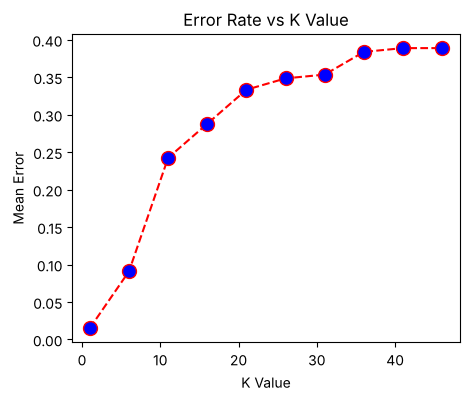

In [4]:
# Error rate for K values between 1 and 50
error = []
for i in range(1, 50, 5):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train, y_train)
    pred_i = knn.predict(X_test)
    error.append(np.mean(pred_i != y_test))

plt.figure(figsize=(5, 4))
plt.plot(range(1, 50, 5), error, color='red', linestyle='dashed', marker='o',
         markerfacecolor='blue', markersize=10)
plt.title('Error Rate vs K Value')
plt.xlabel('K Value')
plt.ylabel('Mean Error')
plt.show()

--- KNN Performance ---
Accuracy: 0.97
Precision: 0.98
Recall: 0.97

Classification Report:
              precision    recall  f1-score   support

         hAd       1.00      1.00      1.00        21
         hEd       0.95      1.00      0.97        19
         hId       1.00      0.94      0.97        18
         hOd       0.95      1.00      0.97        18
         hUd       0.85      0.92      0.88        12
         hYd       1.00      0.95      0.97        19
         had       1.00      1.00      1.00        10
         hed       0.96      1.00      0.98        23
         hid       1.00      1.00      1.00        16
         hod       1.00      0.92      0.96        24
         hud       1.00      1.00      1.00        18

    accuracy                           0.97       198
   macro avg       0.97      0.98      0.97       198
weighted avg       0.98      0.97      0.97       198



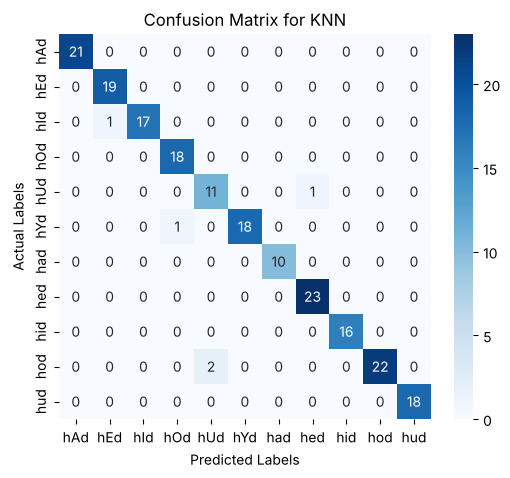

Mean cross-validation score: 0.96


In [5]:
classifier = KNeighborsClassifier(n_neighbors=3)
classifier.fit(X_train, y_train)

evaluate("KNN", classifier.predict(X_test))

scores = cross_val_score(classifier, X, y, cv=cv)
print(f"Mean cross-validation score: {scores.mean():.2f}")

# SVM

Three SVMs are compared:
- **RBF kernel**: a non-linear decision boundary.
- **Soft margin** (linear kernel, C = 1): allows some training points inside the margin.
- **Hard margin** (linear kernel, very large C = 1000): almost no violations allowed.
  The vowel classes are not perfectly linearly separable, so a large C is the closest practical form of a hard margin.

--- SVM RBF Performance ---
Accuracy: 0.95
Precision: 0.96
Recall: 0.95

Classification Report:
              precision    recall  f1-score   support

         hAd       1.00      1.00      1.00        21
         hEd       1.00      0.89      0.94        19
         hId       0.90      1.00      0.95        18
         hOd       0.95      1.00      0.97        18
         hUd       0.77      0.83      0.80        12
         hYd       1.00      0.89      0.94        19
         had       1.00      1.00      1.00        10
         hed       0.88      1.00      0.94        23
         hid       1.00      1.00      1.00        16
         hod       1.00      0.88      0.93        24
         hud       1.00      1.00      1.00        18

    accuracy                           0.95       198
   macro avg       0.95      0.95      0.95       198
weighted avg       0.96      0.95      0.95       198



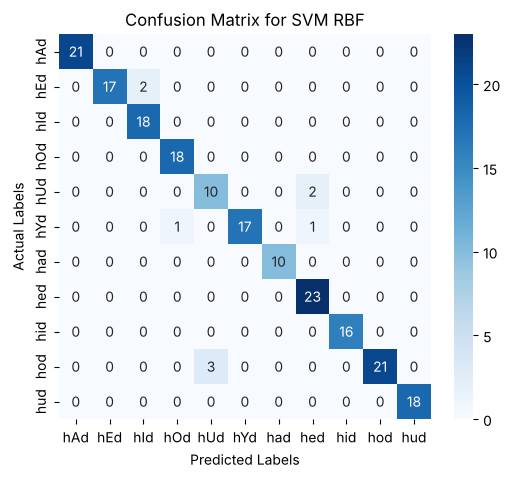

Cross-Validation Accuracy for RBF kernel: 0.95


In [6]:
# Using RBF kernel
model = SVC(kernel='rbf')
model.fit(X_train, y_train)
evaluate("SVM RBF", model.predict(X_test))

cv_scores = cross_val_score(model, X, y, cv=cv)
print(f"Cross-Validation Accuracy for RBF kernel: {cv_scores.mean():.2f}")

--- SVM Soft Margin Performance ---
Accuracy: 0.82
Precision: 0.84
Recall: 0.82

Classification Report:
              precision    recall  f1-score   support

         hAd       1.00      0.95      0.98        21
         hEd       0.85      0.89      0.87        19
         hId       0.79      0.83      0.81        18
         hOd       0.64      0.78      0.70        18
         hUd       0.69      0.92      0.79        12
         hYd       0.82      0.47      0.60        19
         had       0.47      0.70      0.56        10
         hed       0.82      0.78      0.80        23
         hid       0.94      1.00      0.97        16
         hod       0.95      0.79      0.86        24
         hud       1.00      0.89      0.94        18

    accuracy                           0.82       198
   macro avg       0.81      0.82      0.81       198
weighted avg       0.84      0.82      0.82       198



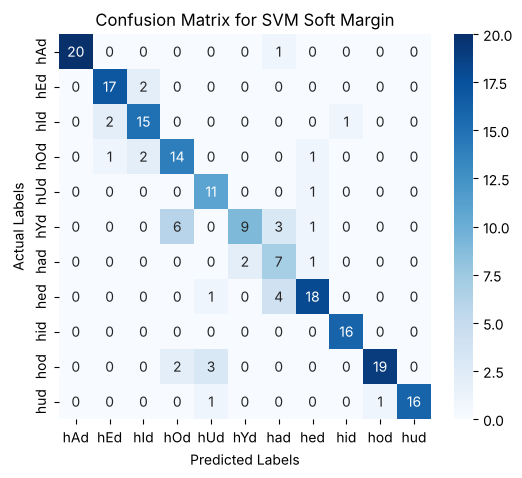

Cross-Validation Accuracy for Soft Margin: 0.80


In [7]:
# Using Soft Margin
model = SVC(kernel='linear', C=1)
model.fit(X_train, y_train)
evaluate("SVM Soft Margin", model.predict(X_test))

cv_scores = cross_val_score(model, X, y, cv=cv)
print(f"Cross-Validation Accuracy for Soft Margin: {cv_scores.mean():.2f}")

--- SVM Hard Margin Performance ---
Accuracy: 0.80
Precision: 0.82
Recall: 0.80

Classification Report:
              precision    recall  f1-score   support

         hAd       0.90      0.90      0.90        21
         hEd       0.85      0.89      0.87        19
         hId       0.88      0.83      0.86        18
         hOd       0.64      0.78      0.70        18
         hUd       0.57      1.00      0.73        12
         hYd       0.91      0.53      0.67        19
         had       0.25      0.30      0.27        10
         hed       0.89      0.74      0.81        23
         hid       0.94      1.00      0.97        16
         hod       0.86      0.75      0.80        24
         hud       1.00      0.94      0.97        18

    accuracy                           0.80       198
   macro avg       0.79      0.79      0.78       198
weighted avg       0.82      0.80      0.80       198



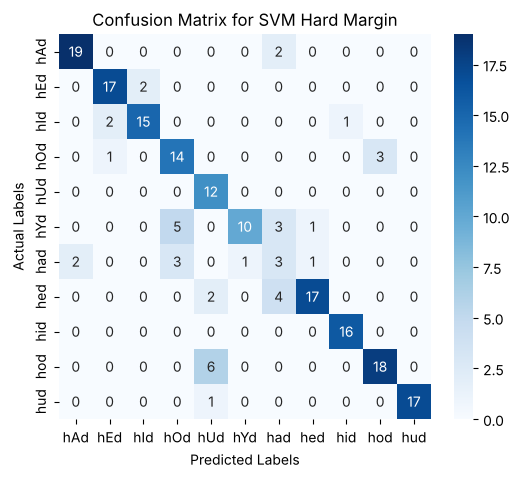

Training accuracy: 0.90  (below 1.00, so the data is not linearly separable)


In [8]:
# Using Hard Margin (very large C)
model = SVC(kernel='linear', C=1000)
model.fit(X_train, y_train)
evaluate("SVM Hard Margin", model.predict(X_test))
print(f"Training accuracy: {model.score(X_train, y_train):.2f}  (below 1.00, so the data is not linearly separable)")

# DeepNN

--- NN Performance ---
Accuracy: 0.99
Precision: 1.00
Recall: 0.99

Classification Report:
              precision    recall  f1-score   support

         hAd       1.00      1.00      1.00        21
         hEd       1.00      1.00      1.00        19
         hId       1.00      1.00      1.00        18
         hOd       1.00      1.00      1.00        18
         hUd       0.92      1.00      0.96        12
         hYd       1.00      1.00      1.00        19
         had       1.00      1.00      1.00        10
         hed       1.00      1.00      1.00        23
         hid       1.00      1.00      1.00        16
         hod       1.00      1.00      1.00        24
         hud       1.00      0.94      0.97        18

    accuracy                           0.99       198
   macro avg       0.99      0.99      0.99       198
weighted avg       1.00      0.99      0.99       198



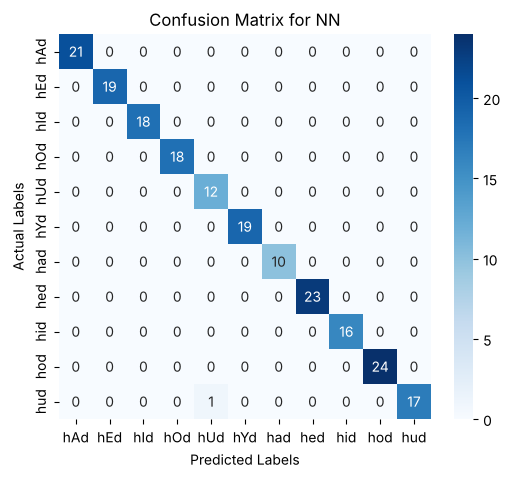

In [9]:
tf.keras.utils.set_random_seed(1)  # same results every run

# Network Architecture
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(len(class_names), activation='softmax'),  # one output per vowel
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model_fit = model.fit(X_train, y_train, epochs=25, batch_size=32, verbose=0)

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
evaluate("NN", y_pred)

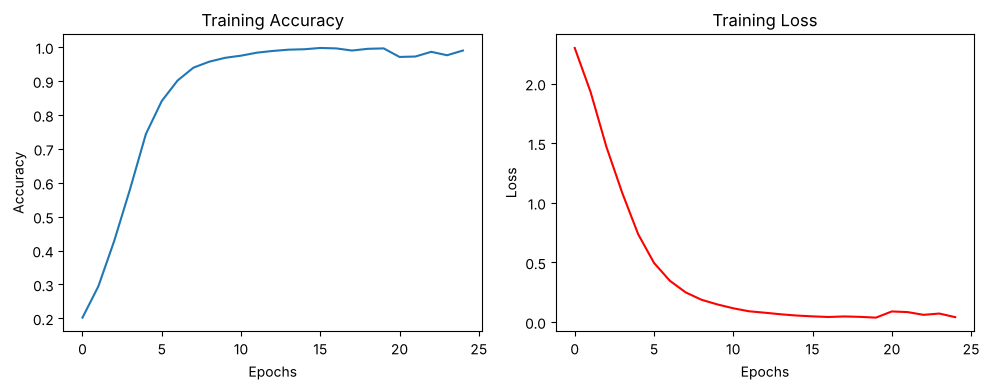

In [10]:
# Training accuracy and loss
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(model_fit.history['accuracy'])
axes[0].set_title('Training Accuracy')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[1].plot(model_fit.history['loss'], color='red')
axes[1].set_title('Training Loss')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
plt.tight_layout()
plt.show()

# Comparison of Models

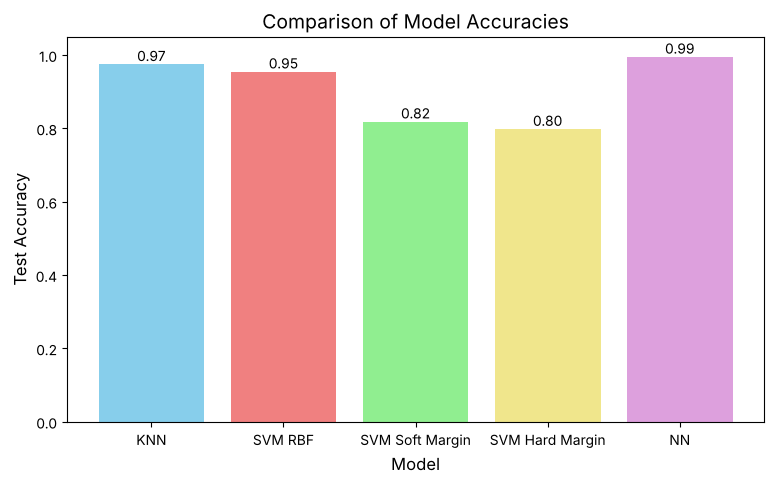

In [11]:
plt.figure(figsize=(9, 5))
bars = plt.bar(results.keys(), results.values(),
               color=['skyblue', 'lightcoral', 'lightgreen', 'khaki', 'plum'])

# Add accuracy values on top of the bars
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
             f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=10)

plt.xlabel("Model", fontsize=12)
plt.ylabel("Test Accuracy", fontsize=12)
plt.title("Comparison of Model Accuracies", fontsize=14)
plt.ylim(0, 1.05)
plt.show()

# Testing on New Speakers

The random split above puts recordings of the **same speakers** in both the training and test sets, so the models
have already "heard" every test speaker. To see how well they work on **people they have never heard**, we use
cross-validation where each fold holds out whole speakers (`GroupKFold`).

In [12]:
group_cv = GroupKFold(n_splits=5)
for name, clf in [("KNN", KNeighborsClassifier(n_neighbors=3)),
                  ("SVM RBF", SVC(kernel='rbf')),
                  ("SVM Soft Margin", SVC(kernel='linear', C=1))]:
    scores = cross_val_score(clf, X, y, cv=group_cv, groups=speakers)
    print(f"{name:16s} accuracy on new speakers: {scores.mean():.2f}")

KNN              accuracy on new speakers: 0.55
SVM RBF          accuracy on new speakers: 0.68
SVM Soft Margin  accuracy on new speakers: 0.57


# Conclusion

| Model | Test accuracy | 5-fold CV | New speakers |
|---|---|---|---|
| Deep NN | 0.99 | - | - |
| KNN (K = 3) | 0.97 | 0.96 | 0.55 |
| SVM RBF | 0.95 | 0.95 | 0.68 |
| SVM Soft Margin | 0.82 | 0.80 | 0.57 |
| SVM Hard Margin (C = 1000) | 0.80 | - | - |

- The **neural network** gave the best test accuracy (0.99), followed by **KNN** (0.97) and the **RBF SVM** (0.95).
- The **linear SVMs** reach only about 0.80 because the vowel classes are not linearly separable. Making the margin harder (larger C) did not help.
- On **speakers the models have never heard**, accuracy drops to 0.55-0.68. The models partly learn each speaker's voice, so more speakers or speaker normalisation would be needed for a real application. The RBF SVM generalises best of the models tested.